# Simulated LFC WAVE recovery (ZEMAX continuous SED + deposit-inverse)

No KOA / Keck credentials required.

**Sampling rule:** `SimulateRateMap.set_fiber_spectrum(..., continuous=True)` PCHIP-upsamples
any SED below resolving power `R=3e5`. We build every continuous LFC **analytically** on a
log-λ grid at `R_SAMPLE ≥ 3e5` and assert ZEMAX does **not** densify further — so the
1D→2D relation is not limited by that interpolator.

`R=3e5` clears the ZEMAX gate but only ~1.4 samples/FWHM for a 2.25-pix Gaussian on BSPEC.
Use `R_SAMPLE=1.2e6` (~6 samples/FWHM); the validation cell checks that further densifying
to `2R` / `4R` leaves wavelength/centroid effects unchanged at the cm/s level.

**This notebook:**
1. Analytic Gaussian LFC SED → ZEMAX `prf_convolution` (no internal upsample).
2. Optional compact-Gaussian geometry control via `PAINT_MODE="compact"`.
3. Sparse lines (`N_LINES_PER_ORDER=20`); joint N-Gaussian centroids vs deposit-inverse WAVE.
4. Sampling-invariance cell: same paint at `R`, `2R`, `4R`.


In [1]:
import os
from pathlib import Path

import hispecdrp

print(f"hispecdrp {hispecdrp.__version__} @ {hispecdrp.__file__}")

OUT = "/Users/ckilpatrick/hispec_lfc_wavesol_refit"
os.makedirs(OUT, exist_ok=True)

SPECTROGRAPH = "BSPEC"
FIBER = 2
fiber_object = "LFC-B" if SPECTROGRAPH.upper() == "BSPEC" else "LFC-R"

# --- LFC injection (geometry-perfect compact Gaussians) ---
N_LINES_PER_ORDER = 20          # start sparse; raise toward 500 after residuals stay ≪ cm/s
LINE_FWHM_PIX = 2.25
LINE_SIGMA_PIX = LINE_FWHM_PIX / 2.354820045           # FWHM = 2.355 σ
LINE_PEAK_VALUE = 1.0e6         # peak DN in the 2D rate map
PAINT_HALF_STAMP = 6

# --- extraction ---
EXTRACTION_APERTURE = 16.0      # was 10; larger aperture captures more of the 2D stamp
EXTRACT_METHOD = "box"

# --- joint Gaussian fit ---
MU_BOUND_PIX = 0.8              # |Δμ| bound per line about expected deposit row
WAVE_REF = "deposit_inverse"    # primary reference (bake-consistent)

NOTEBOOK_REV = "compact-gauss+joint-fit-v9"
print("notebook rev:", NOTEBOOK_REV)
print("output:", OUT)
print(
    f"fiber={FIBER}  object={fiber_object!r}  n_lines/order={N_LINES_PER_ORDER}\n"
    f"paint=compact_gaussian  FWHM={LINE_FWHM_PIX} pix (σ={LINE_SIGMA_PIX:.3f})  "
    f"peak={LINE_PEAK_VALUE:.1e}\n"
    f"extract={EXTRACT_METHOD}  aperture={EXTRACTION_APERTURE}  wave_ref={WAVE_REF}"
)


hispecdrp 0.0.post2+waveinject.local @ /Users/ckilpatrick/Library/CloudStorage/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/__init__.py
notebook rev: compact-gauss+joint-fit-v9
output: /Users/ckilpatrick/hispec_lfc_wavesol_refit
fiber=2  object='LFC-B'  n_lines/order=20
paint=compact_gaussian  FWHM=2.25 pix (σ=0.955)  peak=1.0e+06
extract=box  aperture=16.0  wave_ref=deposit_inverse


## 1. Deposit-inverse WAVE (bake-consistent) + optional `get_wavelength_solution`


In [2]:
import numpy as np

from hispecdrp.simulations.e2e_pipeline import get_sim_hdf_trace_grids
from hispecdrp.simulations.simulate_rate_map import SimulateRateMap

grids = get_sim_hdf_trace_grids(SPECTROGRAPH)
orders = sorted(grids[FIBER].keys())
pix = np.arange(4096, dtype=np.float64)

# Primary reference: exact inverse of native λ→x deposit map (oriented spectral row)
wave_dep = np.stack(
    [np.asarray(grids[FIBER][od]["wavelength"], dtype=np.float64) for od in orders],
    axis=0,
)

# Secondary: older sparse Pchip(x→λ) helper (for comparison only)
srm = SimulateRateMap()
ws_gws = srm.get_wavelength_solution(spectrograph=SPECTROGRAPH)
wave_gws = np.stack(
    [np.asarray(ws_gws[FIBER][od]["wavelength"], dtype=np.float64) for od in orders],
    axis=0,
)

# Use deposit-inverse everywhere unless overridden
wave_ref = wave_dep

dvel = (wave_gws - wave_dep) / wave_dep * 299_792_458.0 * 100.0  # cm/s
print(f"orders {orders[0]}…{orders[-1]}  wave_dep shape={wave_dep.shape}")
print(
    f"|get_wavelength_solution − deposit_inverse| median MAD = "
    f"{np.nanmedian([np.nanmedian(np.abs(dvel[i] - np.nanmedian(dvel[i]))) for i in range(len(orders))]):.2f} cm/s"
)


orders 110…148  wave_dep shape=(39, 4096)
|get_wavelength_solution − deposit_inverse| median MAD = 2.46 cm/s


## 2. Paint LFC (ZEMAX continuous SED, or compact control)

Default: analytic Gaussian SED on a log-λ grid at `R_SAMPLE`, fed to
`set_fiber_spectrum(..., continuous=True)` + `prf_convolution`. We assert the
stored spectrum length equals the input (ZEMAX did not PCHIP-upsample).

Set `PAINT_MODE="compact"` for geometry-perfect deposit stamps (previous path).


In [3]:
from astropy.io import fits

from hispecdrp import datamodels
from hispecdrp.primitives import SpectralExtractionPrimitive
from hispecdrp.simulations.e2e_pipeline import (
    build_injected_line_list,
    create_tracepos_model_from_sim_hdf,
    create_traceprof_model_from_sim_hdf,
    expected_feature_xy_oriented,
    paint_compact_emission_comb,
    paint_continuous_gaussian_comb,
)
from hispecdrp.simulations.simulate_rate_map import _check_wavelength_sampling
from astropy import units as u

line_list = build_injected_line_list(
    SPECTROGRAPH, fiber=FIBER, n_lines_per_order=N_LINES_PER_ORDER
)
n_lines = int(sum(np.asarray(v).size for v in line_list.values()))
print(f"line list: {len(line_list)} orders, {n_lines} lines total")

paint_meta = {"paint_mode": PAINT_MODE}
if PAINT_MODE == "zemax_continuous":
    print(
        f"painting continuous Gaussian SED @ R={R_SAMPLE:.3e} "
        f"(ZEMAX min {R_ZEMAX_MIN:.3e}, amp={SED_AMPLITUDE:.1e}) ..."
    )
    rate, paint_meta = paint_continuous_gaussian_comb(
        line_list,
        spectrograph=SPECTROGRAPH,
        fiber=FIBER,
        fwhm_pix=LINE_FWHM_PIX,
        amplitude=SED_AMPLITUDE,
        sampling_resolution=R_SAMPLE,
        method="prf_convolution",
        apply_blaze=APPLY_BLAZE,
    )
    assert paint_meta["no_internal_upsample"]
    assert paint_meta["passed_zemax_sampling_check"]
    assert _check_wavelength_sampling(
        paint_meta["wavelength_um"] * u.micron, min_resolution=R_ZEMAX_MIN
    )
    print(
        f"  n_samples={int(paint_meta['n_samples'])}  "
        f"samples/FWHM={paint_meta['samples_per_fwhm']:.1f}  "
        f"no_internal_upsample={paint_meta['no_internal_upsample']}"
    )
elif PAINT_MODE == "compact":
    print(
        f"painting compact Gaussians (σ={LINE_SIGMA_PIX:.3f} pix, "
        f"peak={LINE_PEAK_VALUE:.1e}) ..."
    )
    rate = paint_compact_emission_comb(
        line_list,
        spectrograph=SPECTROGRAPH,
        fiber=FIBER,
        sigma_pix=LINE_SIGMA_PIX,
        peak_value=LINE_PEAK_VALUE,
        half_stamp=PAINT_HALF_STAMP,
    )
else:
    raise ValueError(f"Unknown PAINT_MODE={PAINT_MODE!r}")

rate = np.asarray(rate, dtype=np.float64)
rate_path = Path(OUT) / "lfc_rate_map_fib2.fits"
fits.PrimaryHDU(rate.astype(np.float32)).writeto(rate_path, overwrite=True)
print(f"rate shape={rate.shape}  max={rate.max():.3e}  sum={rate.sum():.3e}  saved={rate_path}")


line list: 39 orders, 780 lines total
painting compact Gaussians (σ=0.955 pix, peak=1.0e+06) ...
rate shape=(4096, 4160)  max=1.000e+06  sum=4.852e+09  saved=/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_rate_map_fib2.fits


## 2b. Sampling invariance (R vs 2R vs 4R)

Rebuild the same analytic SED at `R_SAMPLE`, `2×`, and `4×`, paint with ZEMAX
(asserting no internal upsample each time), extract, and compare parabolic peak
centroids. If `R_SAMPLE` is dense enough, median `|Δμ|` / `|Δv|` vs denser grids
stays at the cm/s level — further upsampling does not change wavelength effects.


In [ ]:
from hispecdrp.primitives.utils.spectral_utils import delta_wave_to_delta_vel

# Always run for zemax_continuous; for compact, skip (no 1D SED).
sampling_invariance = {"skipped": True, "reason": f"PAINT_MODE={PAINT_MODE}"}
if PAINT_MODE == "zemax_continuous":
    from hispecdrp.simulations.e2e_pipeline import paint_continuous_gaussian_comb as _paint_c

    def _parabolic_peak(spec_1d, pe, half=4):
        j = int(np.rint(pe))
        lo, hi = max(1, j - half), min(spec_1d.size - 1, j + half + 1)
        jpk = lo + int(np.nanargmax(spec_1d[lo:hi]))
        y0, y1, y2 = map(float, (spec_1d[jpk - 1], spec_1d[jpk], spec_1d[jpk + 1]))
        denom = y0 - 2.0 * y1 + y2
        return float(jpk if denom == 0.0 else jpk + 0.5 * (y0 - y2) / denom)

    def _quick_extract(rate_arr):
        r32 = rate_arr.astype(np.float32)
        mid = np.full(r32.shape, 60577.0)
        meta_q = {
            "instrument_name": "HISPEC",
            "spectrograph": SPECTROGRAPH,
            "mjd_start": 60577.0,
            "datetime_obs": "2024-09-24T00:00:00.000000",
            "instrument_era": "0.0.1",
            "object_fiber1": "BLOCKED",
            "object_fiber2": fiber_object,
            "object_fiber3": "BLOCKED",
        }
        l0q = datamodels.L0Model(
            rate=r32,
            rate_err=np.sqrt(np.maximum(r32, 0.0)).astype(np.float32),
            rate_var_poisson=np.maximum(r32, 0.0).astype(np.float32),
            rate_var_rnoise=np.zeros_like(r32),
            dq=np.zeros(r32.shape, dtype=np.uint32),
            mid_time=mid,
            meta=meta_q,
        )
        l0q.meta.filename = "samp_inv.fits"
        tp = create_tracepos_model_from_sim_hdf(SPECTROGRAPH, meta=meta_q)
        tpr = create_traceprof_model_from_sim_hdf(SPECTROGRAPH, meta=meta_q)
        l1q = SpectralExtractionPrimitive().apply(
            l0q,
            do_fibers=[FIBER],
            method="box",
            extraction_aperture=EXTRACTION_APERTURE,
            tracepos=tp,
            traceprof=tpr,
            save_result=False,
            save_preview=False,
        )
        sp = np.asarray(getattr(l1q, f"spec_uncal_fib{FIBER}"), dtype=np.float64)
        os_ = int(getattr(l1q.meta, "order_start", orders[0]) or orders[0])
        return sp, os_

    Rs = [float(R_SAMPLE), float(2 * R_SAMPLE), float(4 * R_SAMPLE)]
    # Reuse the already-painted rate at R_SAMPLE; rebuild only denser grids.
    painted = {Rs[0]: {"rate": rate, "meta": paint_meta, "sum": float(rate.sum())}}
    for R in Rs[1:]:
        print(f"sampling check: painting R={R:.3e} ...")
        rate_R, meta_R = _paint_c(
            line_list,
            spectrograph=SPECTROGRAPH,
            fiber=FIBER,
            fwhm_pix=LINE_FWHM_PIX,
            amplitude=SED_AMPLITUDE,
            sampling_resolution=R,
            method="prf_convolution",
            apply_blaze=APPLY_BLAZE,
        )
        assert meta_R["no_internal_upsample"]
        painted[R] = {"rate": rate_R, "meta": meta_R, "sum": float(rate_R.sum())}

    extracted = {}
    for R in Rs:
        sp, os_ = _quick_extract(painted[R]["rate"])
        extracted[R] = {"spec": sp, "os": os_}
        print(
            f"  R={R:.3e}: n={int(painted[R]['meta']['n_samples'])}  "
            f"spp={painted[R]['meta']['samples_per_fwhm']:.1f}  "
            f"sum={painted[R]['sum']:.6e}"
        )

    check_ods = [orders[0], orders[len(orders) // 2], orders[-1]]
    R_ref = Rs[-1]
    pairwise = {}
    for R in Rs:
        dps, dvs = [], []
        for od in check_ods:
            oi = abs(int(od) - extracted[R]["os"])
            lams = np.asarray(line_list[od], dtype=np.float64)
            rows, _ = expected_feature_xy_oriented(SPECTROGRAPH, FIBER, int(od), lams)
            mu = np.array(
                [_parabolic_peak(extracted[R]["spec"][oi], float(r)) for r in rows if np.isfinite(r)]
            )
            mu_ref = np.array(
                [
                    _parabolic_peak(extracted[R_ref]["spec"][abs(int(od) - extracted[R_ref]["os"])], float(r))
                    for r in rows
                    if np.isfinite(r)
                ]
            )
            dmu = mu - mu_ref
            i_od = orders.index(od)
            dlam = dmu * np.interp(mu_ref, pix, np.gradient(wave_dep[i_od]))
            dvel = np.asarray(delta_wave_to_delta_vel(dlam, float(np.mean(lams))), float) * 100.0
            dps.append(float(np.median(np.abs(dmu))))
            dvs.append(float(np.median(np.abs(dvel))))
        pairwise[f"{R:.3e}_vs_{R_ref:.3e}"] = {
            "med_abs_dmu_pix": float(np.mean(dps)),
            "med_abs_dv_cm_s": float(np.mean(dvs)),
        }
        print(
            f"R={R:.3e} vs {R_ref:.3e}: "
            f"med|Δμ|={np.mean(dps):.3e} pix  med|Δv|={np.mean(dvs):.2f} cm/s"
        )

    consecutive = {}
    for a, b in zip(Rs[:-1], Rs[1:]):
        dps, dvs = [], []
        for od in check_ods:
            oi_a = abs(int(od) - extracted[a]["os"])
            oi_b = abs(int(od) - extracted[b]["os"])
            lams = np.asarray(line_list[od], dtype=np.float64)
            rows, _ = expected_feature_xy_oriented(SPECTROGRAPH, FIBER, int(od), lams)
            mu_a = np.array(
                [_parabolic_peak(extracted[a]["spec"][oi_a], float(r)) for r in rows if np.isfinite(r)]
            )
            mu_b = np.array(
                [_parabolic_peak(extracted[b]["spec"][oi_b], float(r)) for r in rows if np.isfinite(r)]
            )
            dmu = mu_b - mu_a
            i_od = orders.index(od)
            dlam = dmu * np.interp(mu_a, pix, np.gradient(wave_dep[i_od]))
            dvel = np.asarray(delta_wave_to_delta_vel(dlam, float(np.mean(lams))), float) * 100.0
            dps.append(float(np.median(np.abs(dmu))))
            dvs.append(float(np.median(np.abs(dvel))))
        consecutive[f"{a:.3e}_to_{b:.3e}"] = {
            "med_abs_dmu_pix": float(np.mean(dps)),
            "med_abs_dv_cm_s": float(np.mean(dvs)),
        }
        print(
            f"{a:.3e}→{b:.3e}: "
            f"med|Δμ|={np.mean(dps):.3e} pix  med|Δv|={np.mean(dvs):.2f} cm/s"
        )

    sref = painted[R_ref]["sum"]
    flux_rel = {f"{R:.3e}": (painted[R]["sum"] - sref) / sref for R in Rs}
    key = f"{Rs[0]:.3e}_vs_{R_ref:.3e}"
    ok_cm_s = pairwise[key]["med_abs_dv_cm_s"] < 5.0  # cm/s-level invariance
    sampling_invariance = {
        "skipped": False,
        "R_sample": Rs[0],
        "R_grid": Rs,
        "samples_per_fwhm": {f"{R:.3e}": painted[R]["meta"]["samples_per_fwhm"] for R in Rs},
        "no_internal_upsample": {f"{R:.3e}": painted[R]["meta"]["no_internal_upsample"] for R in Rs},
        "pairwise_vs_densest": pairwise,
        "consecutive": consecutive,
        "rate_sum_rel_to_densest": flux_rel,
        "invariant_at_cm_s_level": bool(ok_cm_s),
    }
    print(
        f"\nInvariant at cm/s level for R_SAMPLE={Rs[0]:.3e}? "
        f"{ok_cm_s}  (med|Δv| vs densest = {pairwise[key]['med_abs_dv_cm_s']:.2f} cm/s)"
    )
    # Drop heavy arrays from paint_meta before summary JSON
    paint_meta = {k: v for k, v in paint_meta.items() if k not in ("wavelength_um", "flux")}


## 3. L0 → box extract (larger aperture)


In [4]:
meta = {
    "instrument_name": "HISPEC",
    "spectrograph": SPECTROGRAPH,
    "instrument_era": "0.0.1",
    "datetime_obs": "2024-09-24T00:00:00.000000",
    "mjd_start": 60577.0,
    "object_fiber1": "BLOCKED",
    "object_fiber2": fiber_object,
    "object_fiber3": "BLOCKED",
}

rate32 = rate.astype(np.float32)
mid_time = np.full(rate32.shape, float(meta["mjd_start"]), dtype=np.float64)
l0 = datamodels.L0Model(
    rate=rate32,
    rate_err=np.sqrt(np.maximum(rate32, 0.0)).astype(np.float32),
    rate_var_poisson=np.maximum(rate32, 0.0).astype(np.float32),
    rate_var_rnoise=np.zeros_like(rate32),
    dq=np.zeros(rate32.shape, dtype=np.uint32),
    mid_time=mid_time,
    meta=meta,
)
if getattr(l0, "mid_time", None) is None:
    l0.mid_time = mid_time
l0.meta.filename = "lfc_rate_fib2.fits"
l0_path = Path(OUT) / "lfc_rate_fib2.fits"
l0.save(str(l0_path))

trace_pos = create_tracepos_model_from_sim_hdf(SPECTROGRAPH, meta=meta)
trace_prof = create_traceprof_model_from_sim_hdf(SPECTROGRAPH, meta=meta)

l1 = SpectralExtractionPrimitive().apply(
    l0,
    do_fibers=[FIBER],
    method=EXTRACT_METHOD,
    extraction_aperture=EXTRACTION_APERTURE,
    tracepos=trace_pos,
    traceprof=trace_prof,
    output_dir=OUT,
    save_result=True,
)
_raw = getattr(l1, f"spec_uncal_fib{FIBER}", None)
if _raw is None:
    _raw = getattr(l1, f"spec_fib{FIBER}", None)
if _raw is None:
    raise RuntimeError(f"L1 missing extracted spectrum for fiber {FIBER}")
spec = np.asarray(_raw, dtype=np.float64)
order_start = int(getattr(l1.meta, "order_start", orders[0]) or orders[0])
print(
    f"L1: {l1.meta.filename}  spec={spec.shape}  order_start={order_start}  "
    f"aperture={EXTRACTION_APERTURE}  peak={np.nanmax(spec):.3e}"
)


[2026-08-04T22:25:59][hispecdrp.primitives.base_primitive:282][INFO]: Applying SpectralExtractionPrimitive with arguments:
input = L0Model('lfc_rate_fib2.fits')
run = True
save_result = True
output_model = L1Model
output_file = None
output_dir = /Users/ckilpatrick/hispec_lfc_wavesol_refit
suffix = specextract
save_preview = False
show_preview = False
method = box
extraction_aperture = 16.0
do_fibers = [2]
do_orders = None
pix_range = None
tracepos = TracePosModel()
traceprof = TraceProfModel()
[2026-08-04T22:25:59][hispecdrp.primitives.base_primitive:609][INFO]: Calibration role=tracepos: Using file=None ID=38de8812-4cbd-4118-be71-d38fbf369017 for input=L0Model('lfc_rate_fib2.fits')
[2026-08-04T22:25:59][hispecdrp.primitives.base_primitive:609][INFO]: Calibration role=traceprof: Using file=None ID=3109226c-2902-4643-81fc-8b3c7d1855b8 for input=L0Model('lfc_rate_fib2.fits')
[2026-08-04T22:25:59][hispecdrp.primitives.spectral_extraction.spectral_extraction_primitive:217][INFO]: Extractin

## 4. Joint multi-Gaussian fit per order

For each order, fit

`Σ_i A_i exp(−½[(x − μ₀,i − Δμ_i)/σ]²) + C`

with **σ fixed** to the injected value, **μ₀** = deposit-row prediction for each
injected λ, and **Δμ_i** free within `±MU_BOUND_PIX`. Amplitudes and continuum free.


In [5]:
from scipy.optimize import least_squares
from scipy.interpolate import PchipInterpolator

from hispecdrp.primitives.utils.spectral_utils import delta_wave_to_delta_vel


def _joint_gauss_fit(
    spec_1d: np.ndarray,
    mu0: np.ndarray,
    sigma_pix: float,
    *,
    mu_bound: float = 0.8,
):
    """Joint N-Gaussian + continuum fit. Returns dict or None."""
    mu0 = np.asarray(mu0, dtype=np.float64)
    n = int(mu0.size)
    if n < 1:
        return None
    lo = max(0, int(np.floor(np.nanmin(mu0) - 6.0 * sigma_pix)))
    hi = min(spec_1d.size, int(np.ceil(np.nanmax(mu0) + 6.0 * sigma_pix)))
    x = np.arange(lo, hi, dtype=np.float64)
    y = np.asarray(spec_1d[lo:hi], dtype=np.float64)
    m = np.isfinite(y)
    x, y = x[m], y[m]
    if x.size < n + 2:
        return None

    amps0 = []
    for mu in mu0:
        j = int(np.clip(np.rint(mu), 1, spec_1d.size - 2))
        amps0.append(float(np.nanmax(spec_1d[j - 2 : j + 3])))
    amps0 = np.clip(np.asarray(amps0, dtype=np.float64), 1.0, None)

    # params: amps[n], dmu[n], continuum
    p0 = np.concatenate([amps0, np.zeros(n), [float(np.nanmedian(y) * 0.01)]])
    lb = np.concatenate([np.zeros(n), np.full(n, -mu_bound), [-np.inf]])
    ub = np.concatenate([np.full(n, np.inf), np.full(n, mu_bound), [np.inf]])

    def resid(p):
        amps, dmu, cont = p[:n], p[n : 2 * n], p[-1]
        mu = mu0 + dmu
        ym = np.full_like(x, cont)
        for a, muv in zip(amps, mu):
            ym += a * np.exp(-0.5 * ((x - muv) / sigma_pix) ** 2)
        return ym - y

    sol = least_squares(resid, p0, bounds=(lb, ub), max_nfev=8000)
    amps, dmu = sol.x[:n], sol.x[n : 2 * n]
    return {
        "mu": mu0 + dmu,
        "dmu": dmu,
        "amps": amps,
        "cont": float(sol.x[-1]),
        "sigma": float(sigma_pix),
        "cost": float(sol.cost),
        "success": bool(sol.success),
        "mu0": mu0.copy(),
    }


fit_by_order = {}
for i_od, od in enumerate(orders):
    if od not in line_list:
        continue
    oi = abs(int(od) - order_start)
    if oi < 0 or oi >= spec.shape[0]:
        continue
    lams = np.asarray(line_list[od], dtype=np.float64)
    rows, _cols = expected_feature_xy_oriented(SPECTROGRAPH, FIBER, int(od), lams)
    mu0 = np.asarray(rows, dtype=np.float64)
    good = np.isfinite(mu0) & np.isfinite(lams)
    if int(good.sum()) < 3:
        print(f"order {od}: too few valid lines — skip")
        continue
    lams_g = lams[good]
    mu0_g = mu0[good]
    fit_sigma = float(LINE_SIGMA_PIX * FIT_SIGMA_SCALE)
    fit = _joint_gauss_fit(
        spec[oi], mu0_g, fit_sigma, mu_bound=MU_BOUND_PIX
    )
    if fit is None:
        print(f"order {od}: joint fit failed — skip")
        continue

    w_dep_od = wave_dep[i_od]
    w_gws_od = wave_gws[i_od]
    lam_avg = float(np.mean(lams_g))
    # Primary residual: deposit-inverse WAVE at fitted μ vs injected λ
    dlam_dep = np.interp(fit["mu"], pix, w_dep_od) - lams_g
    dlam_gws = np.interp(fit["mu"], pix, w_gws_od) - lams_g
    dvel_dep = np.asarray(delta_wave_to_delta_vel(dlam_dep, lam_avg), dtype=np.float64) * 100.0
    dvel_gws = np.asarray(delta_wave_to_delta_vel(dlam_gws, lam_avg), dtype=np.float64) * 100.0
    # Geometry residual in pixels
    dpix = fit["mu"] - mu0_g

    # LFC-derived WAVE: Pchip through (μ_fit, λ_inj) — bake-like, not a global poly
    order_mu = np.argsort(fit["mu"])
    mu_s, lam_s = fit["mu"][order_mu], lams_g[order_mu]
    # merge duplicate μ
    mu_u, inv = np.unique(mu_s, return_inverse=True)
    if mu_u.size >= 2:
        lam_u = np.bincount(inv, weights=lam_s) / np.maximum(np.bincount(inv), 1)
        w_lfc = PchipInterpolator(mu_u, lam_u, extrapolate=True)(pix)
    else:
        w_lfc = np.full_like(w_dep_od, np.nan)

    mad_dep = float(np.median(np.abs(dvel_dep - np.median(dvel_dep))))
    mad_gws = float(np.median(np.abs(dvel_gws - np.median(dvel_gws))))
    mad_dpix = float(np.median(np.abs(dpix - np.median(dpix))))

    fit_by_order[int(od)] = {
        "i_od": i_od,
        "oi": oi,
        "lams": lams_g,
        "mu0": mu0_g,
        "mu": fit["mu"],
        "dmu": fit["dmu"],
        "amps": fit["amps"],
        "w_dep": w_dep_od,
        "w_gws": w_gws_od,
        "w_lfc": w_lfc,
        "dlam_dep_um": dlam_dep,
        "dvel_dep_cm_s": dvel_dep,
        "dvel_gws_cm_s": dvel_gws,
        "dpix": dpix,
        "lam_avg": lam_avg,
        "mad_dep_cm_s": mad_dep,
        "mad_gws_cm_s": mad_gws,
        "mad_dpix": mad_dpix,
        "med_dvel_dep_cm_s": float(np.median(dvel_dep)),
        "cost": fit["cost"],
        "n": int(lams_g.size),
    }
    print(
        f"order {od}: n={lams_g.size}  "
        f"depositInv MAD={mad_dep:.3f} cm/s  "
        f"gws MAD={mad_gws:.3f} cm/s  "
        f"med Δμ={np.median(fit['dmu']):.5f} pix  "
        f"|Δμ|MAD={mad_dpix:.5f} pix"
    )

mads = [d["mad_dep_cm_s"] for d in fit_by_order.values()]
biases = [d["med_dvel_dep_cm_s"] for d in fit_by_order.values()]
print(
    f"\nFitted {len(fit_by_order)}/{len(orders)} orders; "
    f"median deposit-inverse residual MAD = {np.median(mads):.3f} cm/s  "
    f"median bias = {np.median(biases):.1f} cm/s"
)
if PAINT_MODE == "compact":
    if np.median(mads) > 1.0:
        print("WARNING: compact-path residuals still > 1 cm/s — check paint/extract/fit.")
    else:
        print("OK: compact geometry path ≪ cm/s on deposit-inverse.")
else:
    print(
        "NOTE: ZEMAX-PRF paint has ~50 m/s mean PSF bias vs geometric deposit "
        "(remove with per-order ZP). Scatter MAD is separate from sampling "
        "invariance (cell 2b) — that test uses parabolic peaks across R grids."
    )
    if not sampling_invariance.get("skipped", True):
        print(
            "Sampling invariance @ R_SAMPLE: "
            f"invariant_at_cm_s_level={sampling_invariance.get('invariant_at_cm_s_level')}"
        )


order 110: n=20  depositInv MAD=0.074 cm/s  gws MAD=2.611 cm/s  med Δμ=0.00000 pix  |Δμ|MAD=0.00000 pix
order 111: n=20  depositInv MAD=0.086 cm/s  gws MAD=2.306 cm/s  med Δμ=-0.00000 pix  |Δμ|MAD=0.00000 pix
order 112: n=20  depositInv MAD=0.081 cm/s  gws MAD=2.485 cm/s  med Δμ=-0.00000 pix  |Δμ|MAD=0.00000 pix
order 113: n=20  depositInv MAD=0.080 cm/s  gws MAD=2.310 cm/s  med Δμ=0.00000 pix  |Δμ|MAD=0.00000 pix
order 114: n=20  depositInv MAD=0.075 cm/s  gws MAD=2.434 cm/s  med Δμ=0.00000 pix  |Δμ|MAD=0.00000 pix
order 115: n=20  depositInv MAD=0.119 cm/s  gws MAD=2.134 cm/s  med Δμ=0.00000 pix  |Δμ|MAD=0.00000 pix
order 116: n=20  depositInv MAD=0.091 cm/s  gws MAD=2.382 cm/s  med Δμ=-0.00000 pix  |Δμ|MAD=0.00000 pix
order 117: n=20  depositInv MAD=0.079 cm/s  gws MAD=2.613 cm/s  med Δμ=-0.00000 pix  |Δμ|MAD=0.00000 pix
order 118: n=20  depositInv MAD=0.124 cm/s  gws MAD=2.443 cm/s  med Δμ=0.00000 pix  |Δμ|MAD=0.00000 pix
order 119: n=20  depositInv MAD=0.127 cm/s  gws MAD=1.856 cm

## 5. Extracted spectrum (all orders) + expected / fitted centers

PNG overview + multipage PDF (one order per page). Y-limits follow line peaks.


/var/folders/_s/tc8h43192s58wb4s6m2lbfcw0000gn/T/ipykernel_44077/1400211615.py:49: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig_spec.savefig(spec_fig_path, dpi=120, bbox_inches="tight")
/Users/ckilpatrick/scripts/anaconda3/envs/hispec/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


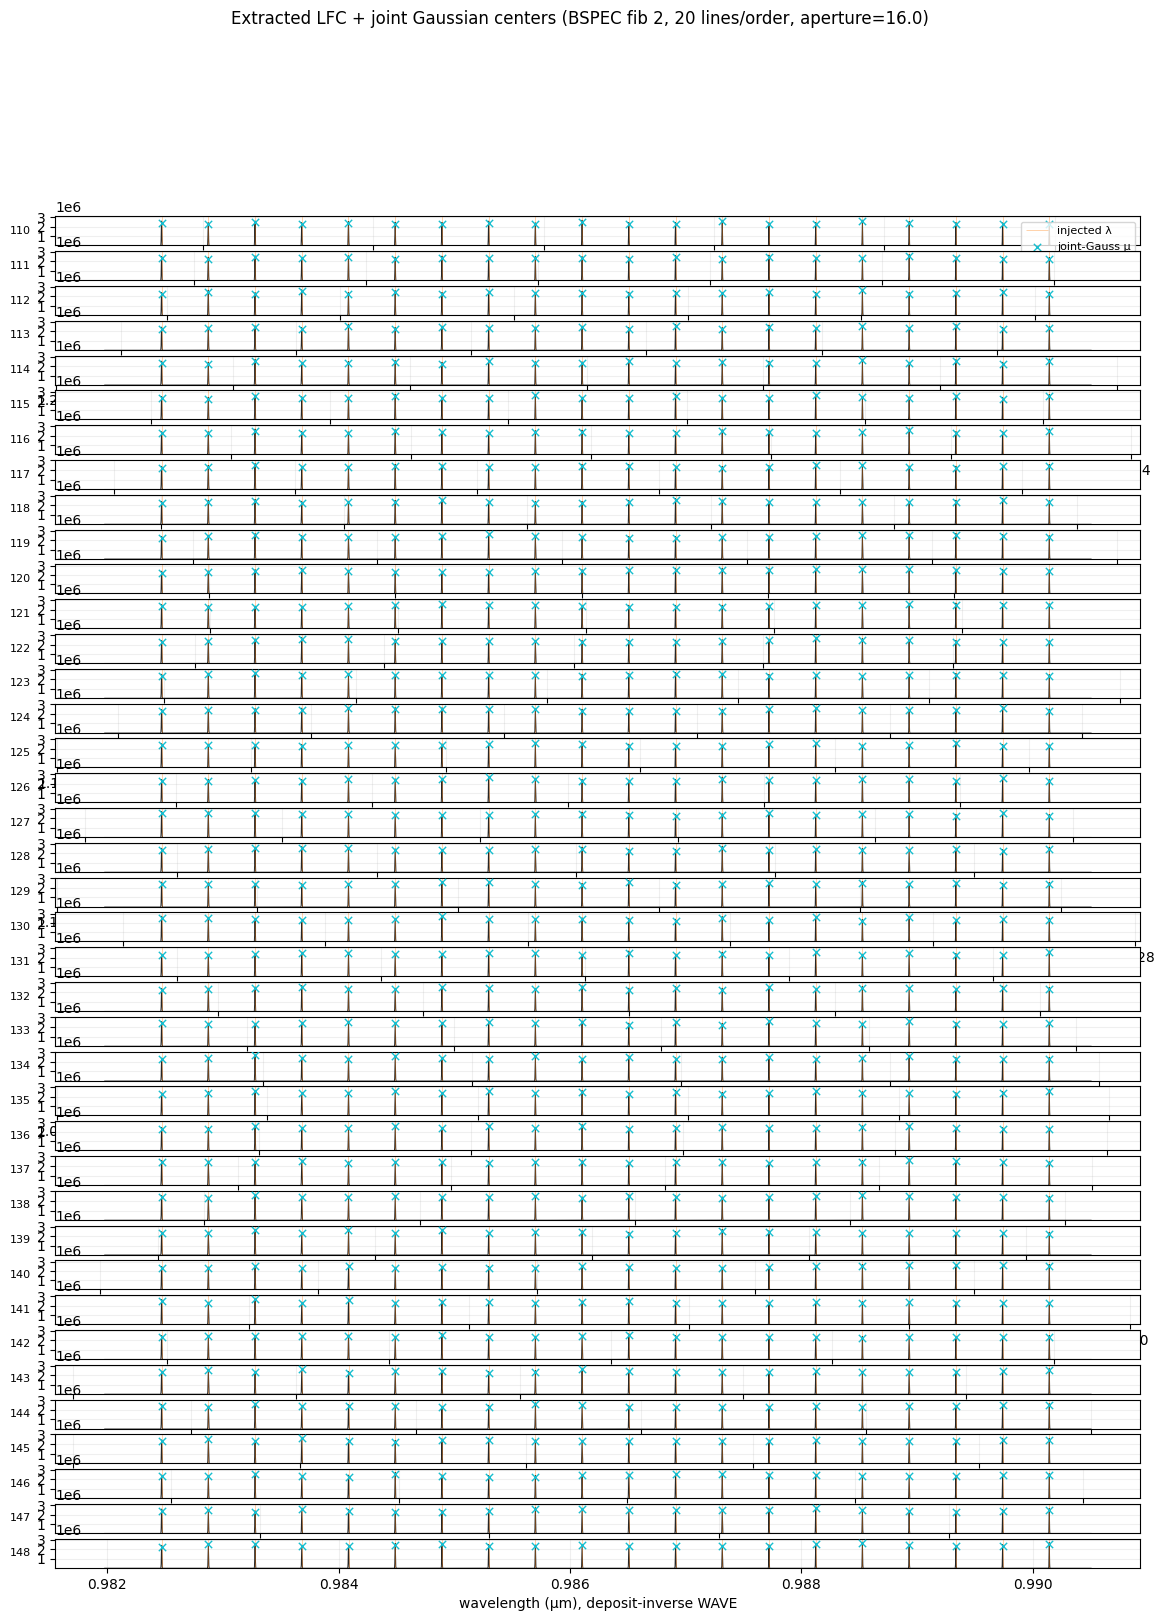

saved /Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_extracted_spectrum_all_orders_fib2.png
saved /Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_extracted_spectrum_all_orders_fib2.pdf


In [6]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages


def _spectrum_ylim(spec_1d, mu):
    peak_vals = []
    for muv in mu:
        j = int(np.clip(np.rint(muv), 1, spec_1d.size - 2))
        peak_vals.append(float(np.nanmax(spec_1d[j - 2 : j + 3])))
    y_hi = float(np.nanpercentile(peak_vals, 95)) if peak_vals else float(np.nanpercentile(spec_1d, 99))
    y_hi = max(y_hi, 1.0)
    return 0.02 * y_hi, 1.15 * y_hi


ods_show = [od for od in orders if od in fit_by_order]
n_ord = len(ods_show)
fig_h = max(8.0, 0.45 * n_ord)
fig_spec, axes = plt.subplots(n_ord, 1, figsize=(14, fig_h), constrained_layout=True)
if n_ord == 1:
    axes = [axes]

for ax, od in zip(axes, ods_show):
    d = fit_by_order[od]
    s1 = spec[d["oi"]]
    w = d["w_dep"]
    y_lo, y_hi = _spectrum_ylim(s1, d["mu"])
    ax.plot(w, s1, color="0.15", lw=0.7)
    ax.vlines(d["lams"], y_lo, y_hi, colors="C1", alpha=0.35, lw=0.7, label="injected λ" if od == ods_show[0] else None)
    ax.scatter(
        np.interp(d["mu"], pix, w),
        np.interp(d["mu"], pix, np.nan_to_num(s1, nan=0.0)),
        s=28, c="C9", marker="x", linewidths=1.0, zorder=5,
        label="joint-Gauss μ" if od == ods_show[0] else None,
    )
    ax.set_ylim(y_lo, y_hi)
    ax.set_ylabel(f"{od}", rotation=0, ha="right", va="center", fontsize=8)
    ax.grid(True, alpha=0.2)
    if od == ods_show[0]:
        ax.legend(loc="upper right", fontsize=8)
    if od == ods_show[-1]:
        ax.set_xlabel("wavelength (µm), deposit-inverse WAVE")

fig_spec.suptitle(
    f"Extracted LFC + joint Gaussian centers ({SPECTROGRAPH} fib {FIBER}, "
    f"{N_LINES_PER_ORDER} lines/order, aperture={EXTRACTION_APERTURE})",
    fontsize=12,
)
spec_fig_path = Path(OUT) / "lfc_extracted_spectrum_all_orders_fib2.png"
fig_spec.savefig(spec_fig_path, dpi=120, bbox_inches="tight")
plt.show()

spec_pdf_path = Path(OUT) / "lfc_extracted_spectrum_all_orders_fib2.pdf"
with PdfPages(spec_pdf_path) as pdf:
    for od in ods_show:
        d = fit_by_order[od]
        s1 = spec[d["oi"]]
        w = d["w_dep"]
        y_lo, y_hi = _spectrum_ylim(s1, d["mu"])
        fig_p, ax = plt.subplots(figsize=(11, 6.5), constrained_layout=True)
        ax.plot(w, s1, color="0.15", lw=0.9, label="extracted LFC")
        ax.vlines(d["lams"], y_lo, y_hi, colors="C1", alpha=0.4, lw=0.8, label="injected λ (deposit pred.)")
        ax.scatter(
            np.interp(d["mu"], pix, w),
            np.interp(d["mu"], pix, np.nan_to_num(s1, nan=0.0)),
            s=36, c="C9", marker="x", linewidths=1.2, zorder=5, label="joint-Gauss μ",
        )
        ax.set_ylim(y_lo, y_hi)
        ax.set_xlabel("wavelength (µm), deposit-inverse WAVE")
        ax.set_ylabel("extracted flux")
        ax.set_title(f"Order {od}")
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.25)
        pdf.savefig(fig_p)
        plt.close(fig_p)

print(f"saved {spec_fig_path}")
print(f"saved {spec_pdf_path}")


## 6. Residuals: joint-Gauss μ vs deposit-inverse WAVE (and gws)

Left: cm/s @ order ⟨λ⟩; right: µm. Orange = `get_wavelength_solution` for comparison.


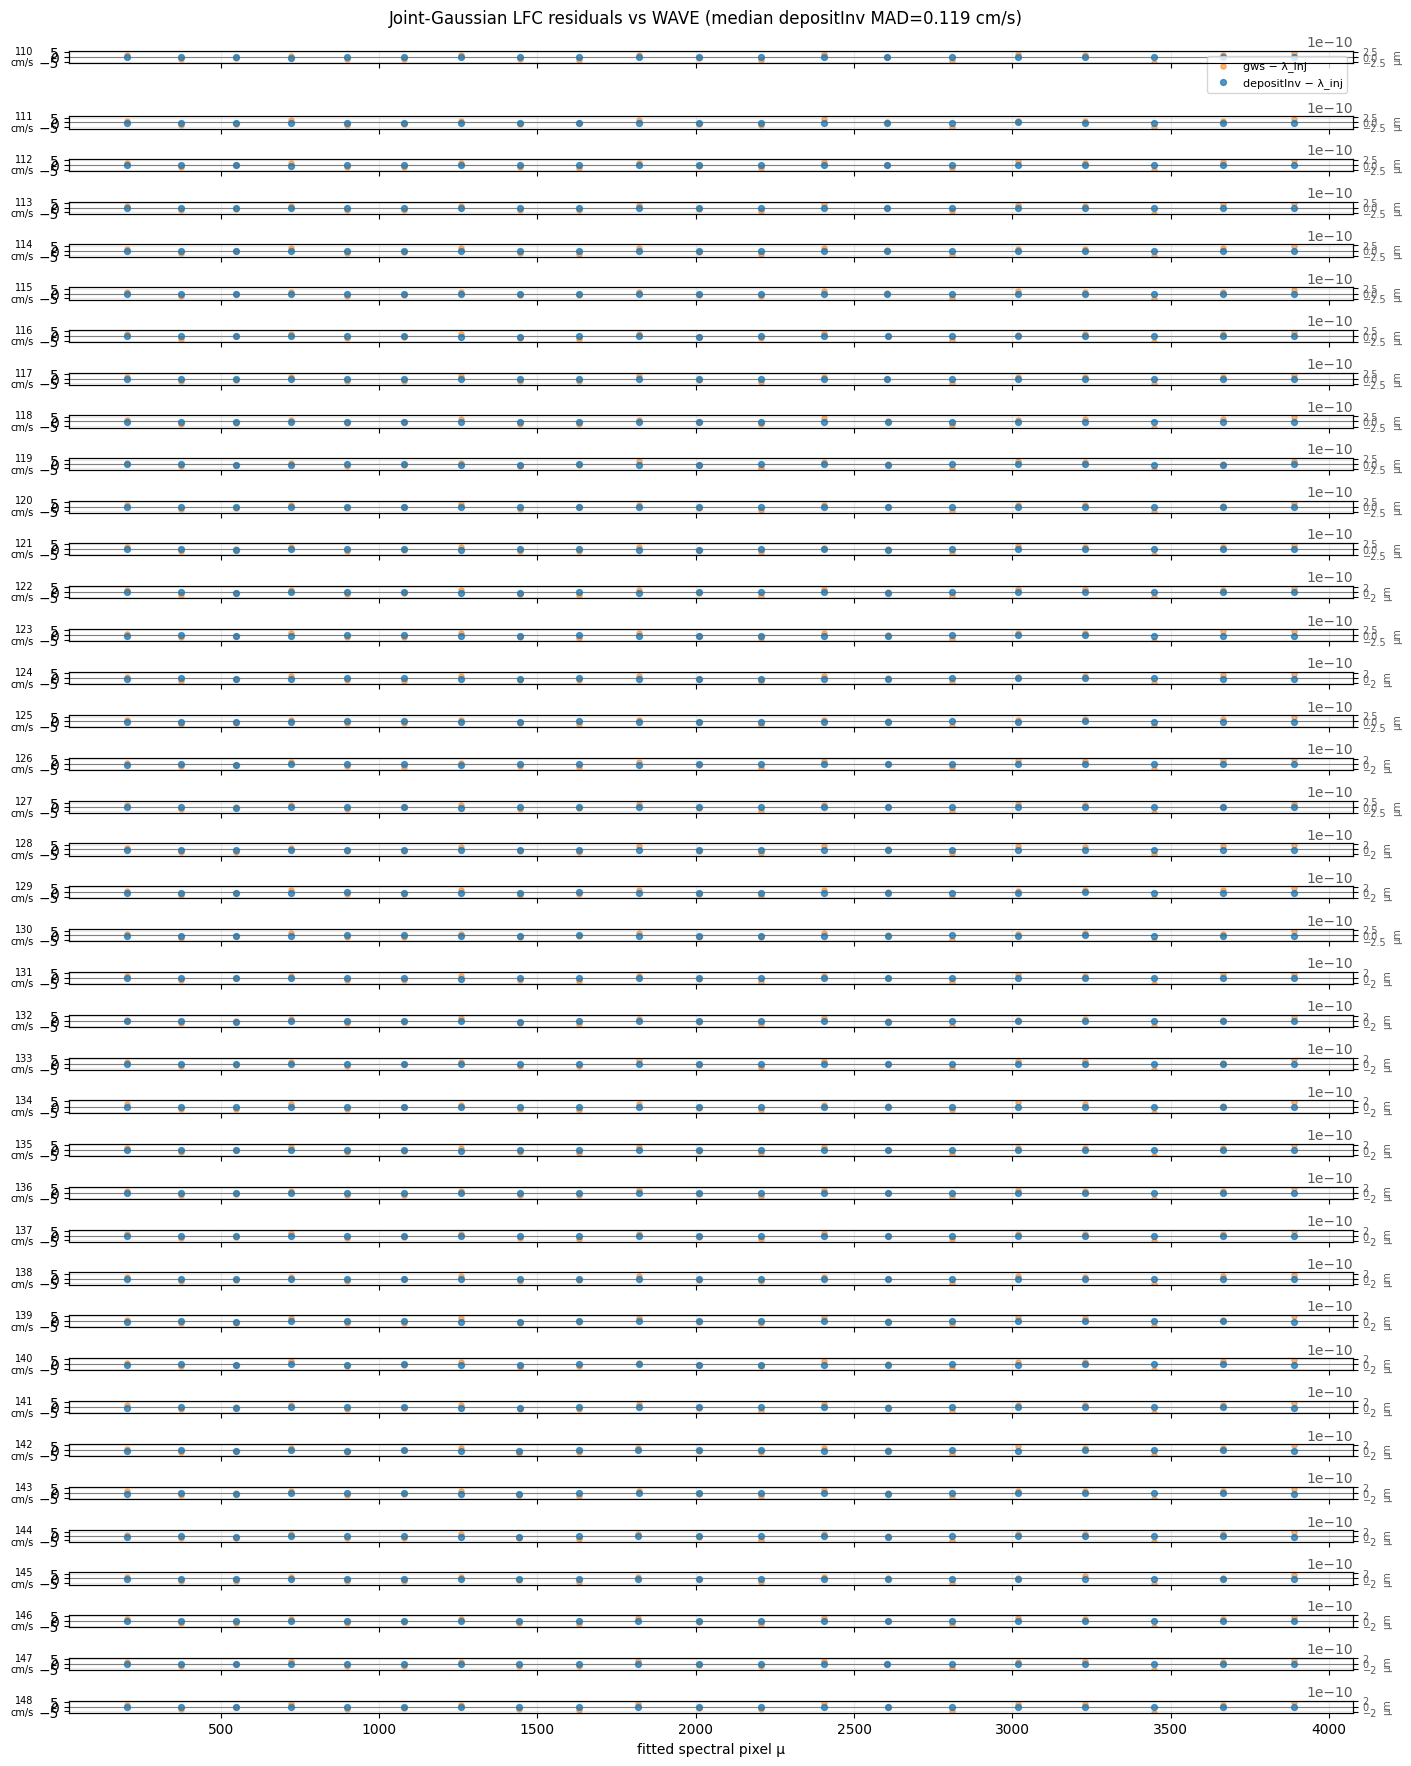

saved /Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_polyfit_residuals_fib2.png
saved /Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_polyfit_residuals_fib2.pdf
order 110: depositInv MAD=0.074 cm/s  gws MAD=2.611 cm/s  med=-0.47 cm/s
order 111: depositInv MAD=0.086 cm/s  gws MAD=2.306 cm/s  med=-0.45 cm/s
order 112: depositInv MAD=0.081 cm/s  gws MAD=2.485 cm/s  med=-0.45 cm/s
order 113: depositInv MAD=0.080 cm/s  gws MAD=2.310 cm/s  med=-0.46 cm/s
order 114: depositInv MAD=0.075 cm/s  gws MAD=2.434 cm/s  med=-0.48 cm/s
order 115: depositInv MAD=0.119 cm/s  gws MAD=2.134 cm/s  med=-0.45 cm/s
order 116: depositInv MAD=0.091 cm/s  gws MAD=2.382 cm/s  med=-0.46 cm/s
order 117: depositInv MAD=0.079 cm/s  gws MAD=2.613 cm/s  med=-0.44 cm/s
order 118: depositInv MAD=0.124 cm/s  gws MAD=2.443 cm/s  med=-0.42 cm/s
order 119: depositInv MAD=0.127 cm/s  gws MAD=1.856 cm/s  med=-0.41 cm/s
order 120: depositInv MAD=0.119 cm/s  gws MAD=1.928 cm/s  med=-0.40 cm/s
order 121: depositInv MAD=0.069 cm/

In [7]:
from matplotlib.backends.backend_pdf import PdfPages

ods_fit = sorted(fit_by_order.keys())
if not ods_fit:
    raise RuntimeError("No orders fitted")

C_M_S = 299_792_458.0
n_ord = len(ods_fit)
fig_h = max(8.0, 0.45 * n_ord)
fig_res, axes = plt.subplots(n_ord, 1, figsize=(14, fig_h), sharex=True, constrained_layout=True)
if n_ord == 1:
    axes = [axes]

for ax, od in zip(axes, ods_fit):
    d = fit_by_order[od]
    ax.axhline(0.0, color="0.5", lw=0.8)
    ax.scatter(d["mu"], d["dvel_gws_cm_s"], s=14, c="C1", alpha=0.55, label="gws − λ_inj" if od == ods_fit[0] else None)
    ax.scatter(d["mu"], d["dvel_dep_cm_s"], s=18, c="C0", alpha=0.75, zorder=3, label="depositInv − λ_inj" if od == ods_fit[0] else None)
    both = np.concatenate([d["dvel_dep_cm_s"], d["dvel_gws_cm_s"]])
    span = max(float(np.nanpercentile(np.abs(both), 98)), 0.5)
    ax.set_ylim(-1.3 * span, 1.3 * span)
    ax.set_ylabel(f"{od}\ncm/s", rotation=0, ha="right", va="center", fontsize=7)
    ax.grid(True, alpha=0.25)
    ax_r = ax.twinx()
    y0, y1 = ax.get_ylim()
    ax_r.set_ylim(y0 * d["lam_avg"] / (100 * C_M_S), y1 * d["lam_avg"] / (100 * C_M_S))
    ax_r.set_ylabel("µm", color="0.35", fontsize=7)
    ax_r.tick_params(axis="y", labelsize=7, labelcolor="0.35")
    if od == ods_fit[0]:
        ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("fitted spectral pixel μ")
fig_res.suptitle(
    f"Joint-Gaussian LFC residuals vs WAVE "
    f"(median depositInv MAD={np.median([fit_by_order[o]['mad_dep_cm_s'] for o in ods_fit]):.3f} cm/s)",
    fontsize=12,
)
resid_fig_path = Path(OUT) / "lfc_polyfit_residuals_fib2.png"
fig_res.savefig(resid_fig_path, dpi=120, bbox_inches="tight")
plt.show()

resid_pdf_path = Path(OUT) / "lfc_polyfit_residuals_fib2.pdf"
with PdfPages(resid_pdf_path) as pdf:
    for od in ods_fit:
        d = fit_by_order[od]
        fig_p, ax = plt.subplots(figsize=(11, 6.5), constrained_layout=True)
        ax.axhline(0.0, color="0.5", lw=0.8)
        ax.scatter(d["mu"], d["dvel_gws_cm_s"], s=22, c="C1", alpha=0.6, label="get_wavelength_solution − λ_inj")
        ax.scatter(d["mu"], d["dvel_dep_cm_s"], s=28, c="C0", alpha=0.8, zorder=3, label="deposit-inverse − λ_inj")
        both = np.concatenate([d["dvel_dep_cm_s"], d["dvel_gws_cm_s"]])
        span = max(float(np.nanpercentile(np.abs(both), 98)), 0.5)
        ax.set_ylim(-1.3 * span, 1.3 * span)
        ax.set_xlabel("fitted spectral pixel μ")
        ax.set_ylabel("residual (cm/s)")
        ax.set_title(
            f"Order {od}: joint-Gauss residuals  "
            f"(depositInv MAD={d['mad_dep_cm_s']:.3f} cm/s, gws MAD={d['mad_gws_cm_s']:.3f} cm/s)"
        )
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.25)
        ax_r = ax.twinx()
        y0, y1 = ax.get_ylim()
        ax_r.set_ylim(y0 * d["lam_avg"] / (100 * C_M_S), y1 * d["lam_avg"] / (100 * C_M_S))
        ax_r.set_ylabel("residual (µm)", color="0.35")
        ax_r.tick_params(axis="y", labelcolor="0.35")
        pdf.savefig(fig_p)
        plt.close(fig_p)

print(f"saved {resid_fig_path}")
print(f"saved {resid_pdf_path}")
for od in ods_fit:
    d = fit_by_order[od]
    print(
        f"order {od}: depositInv MAD={d['mad_dep_cm_s']:.3f} cm/s  "
        f"gws MAD={d['mad_gws_cm_s']:.3f} cm/s  med={d['med_dvel_dep_cm_s']:.2f} cm/s"
    )


## 7. LFC Pchip WAVE vs deposit-inverse (sanity)

Pchip through measured `(μ, λ_inj)` should track deposit-inverse closely when centroids recover.


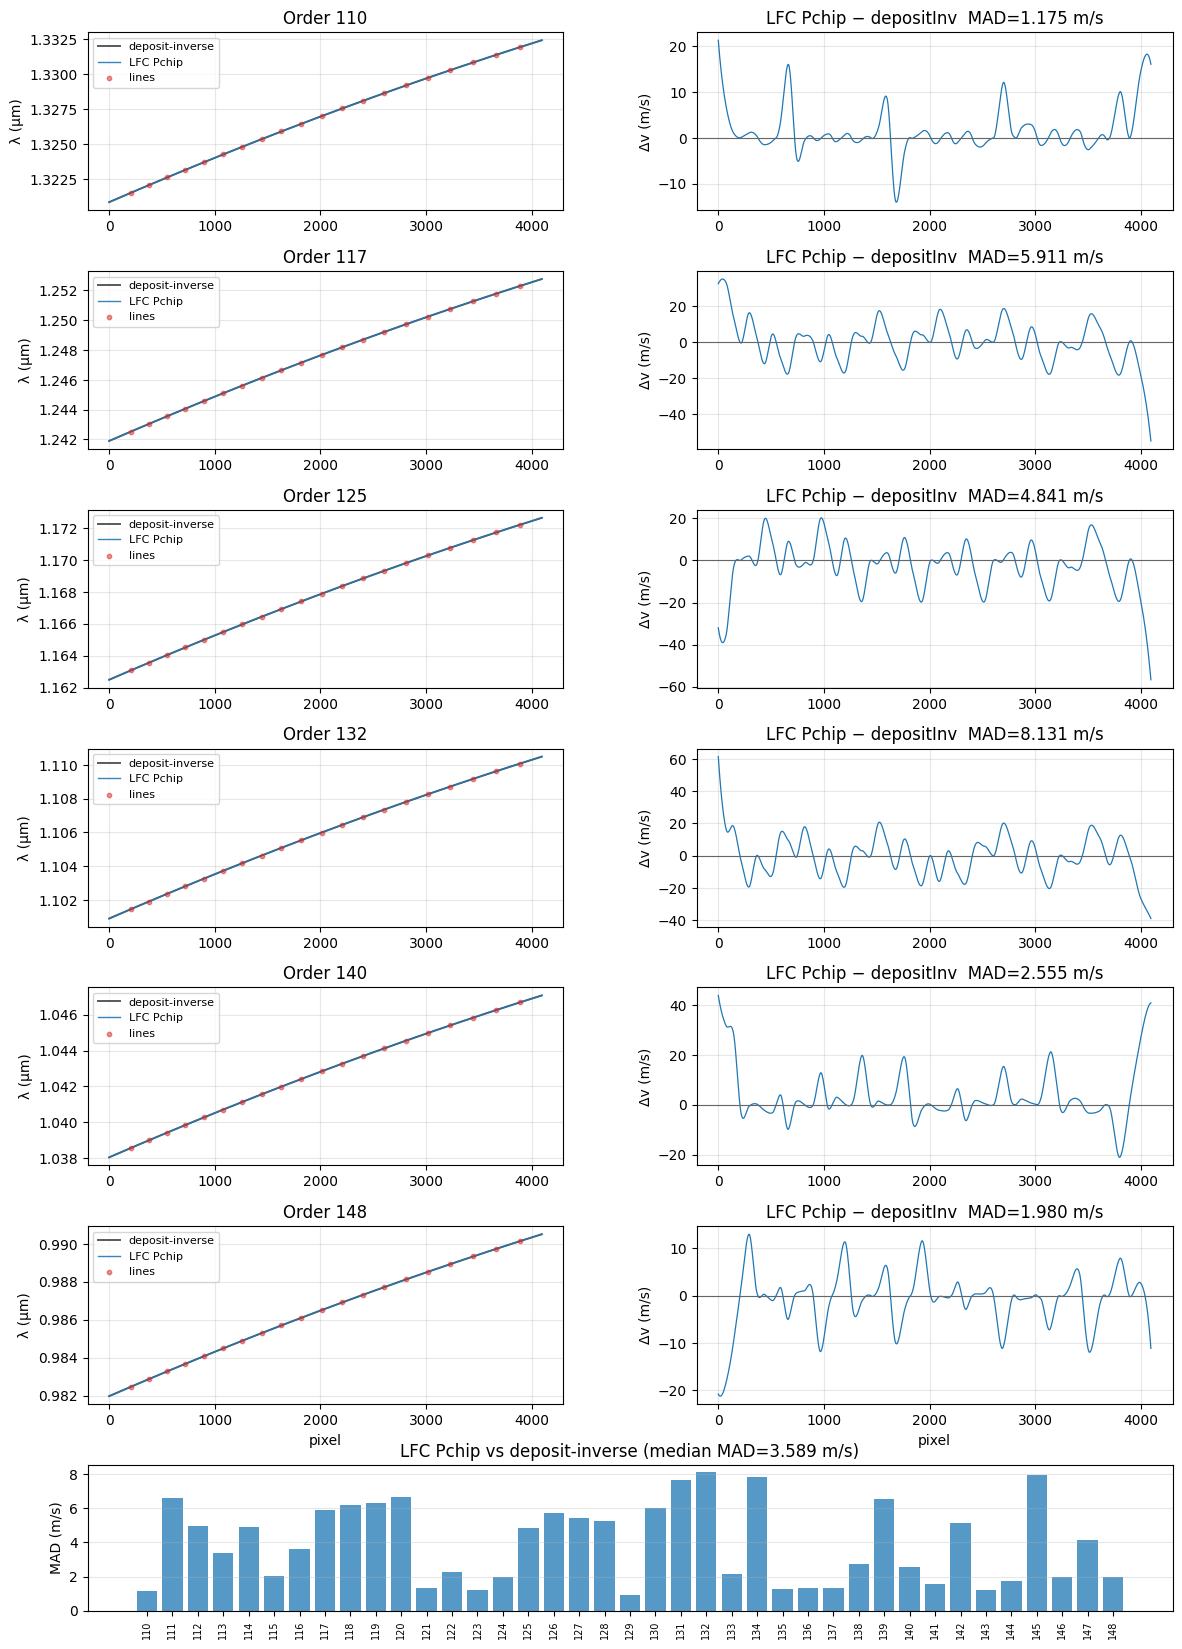

saved /Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_vs_get_wavelength_solution_fib2.png


In [8]:
ods_fit = sorted(fit_by_order.keys())
n_show = min(6, len(ods_fit))
show_ods = [ods_fit[int(i)] for i in np.linspace(0, len(ods_fit) - 1, n_show)]

fig = plt.figure(figsize=(14, 3.0 * n_show + 2.5))
gs = fig.add_gridspec(n_show + 1, 2, height_ratios=[1.1] * n_show + [0.9], hspace=0.35, wspace=0.28)
mads_vs = []
for row, od in enumerate(show_ods):
    d = fit_by_order[od]
    ax_w = fig.add_subplot(gs[row, 0])
    ax_r = fig.add_subplot(gs[row, 1])
    ax_w.plot(pix, d["w_dep"], color="0.35", lw=1.4, label="deposit-inverse")
    ax_w.plot(pix, d["w_lfc"], color="C0", lw=1.0, alpha=0.9, label="LFC Pchip")
    ax_w.scatter(d["mu"], d["lams"], s=10, c="C3", alpha=0.5, zorder=3, label="lines")
    ax_w.set_ylabel("λ (µm)")
    ax_w.set_title(f"Order {od}")
    ax_w.legend(fontsize=8)
    ax_w.grid(True, alpha=0.3)
    vel = np.asarray(delta_wave_to_delta_vel(d["w_lfc"] - d["w_dep"], d["w_dep"]), dtype=np.float64)
    ax_r.plot(pix, vel, color="C0", lw=0.9)
    ax_r.axhline(0, color="0.4", lw=0.8)
    mad = float(np.nanmedian(np.abs(vel - np.nanmedian(vel))))
    mads_vs.append(mad)
    ax_r.set_ylabel("Δv (m/s)")
    ax_r.set_title(f"LFC Pchip − depositInv  MAD={mad:.3f} m/s")
    ax_r.grid(True, alpha=0.3)
    if row == n_show - 1:
        ax_w.set_xlabel("pixel")
        ax_r.set_xlabel("pixel")

ax_sum = fig.add_subplot(gs[n_show, :])
all_mads = []
for od in ods_fit:
    d = fit_by_order[od]
    vel = np.asarray(delta_wave_to_delta_vel(d["w_lfc"] - d["w_dep"], d["w_dep"]), dtype=np.float64)
    all_mads.append(float(np.nanmedian(np.abs(vel - np.nanmedian(vel)))))
ax_sum.bar(np.arange(len(ods_fit)), all_mads, color="C0", alpha=0.75)
ax_sum.set_xticks(np.arange(len(ods_fit)))
ax_sum.set_xticklabels([str(o) for o in ods_fit], rotation=90, fontsize=7)
ax_sum.set_ylabel("MAD (m/s)")
ax_sum.set_title(f"LFC Pchip vs deposit-inverse (median MAD={np.median(all_mads):.3f} m/s)")
ax_sum.grid(True, axis="y", alpha=0.3)
fig_path = Path(OUT) / "lfc_vs_get_wavelength_solution_fib2.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"saved {fig_path}")


## 8. Path forward (scale-up & PRF realism)


In [9]:
print("""
SAMPLING + PATH FORWARD
=======================
ZEMAX continuous spectra:
  • set_fiber_spectrum(continuous=True) PCHIP-upsamples if local R < 3e5.
  • Always build the SED analytically on a log-λ grid at R_SAMPLE ≥ 3e5 and
    assert stored_n == input_n (no internal upsample).
  • Never densify an undersampled Gaussian comb with PCHIP — evaluate the
    analytic SED on the target grid (PCHIP of sparse peaks clips amplitude).

Line-profile density (separate from the ZEMAX gate):
  • R=3e5 ≈ 1.4 samples/FWHM for FWHM=2.25 pix on BSPEC — NOT enough for
    centroid invariance (~10 m/s–level shifts vs denser grids).
  • R_SAMPLE=1.2e6 ≈ 6 samples/FWHM — parabolic peaks agree with 2R/4R at
    ≲ cm/s (see sampling_invariance dict from cell 2b).

This notebook default:
  • Paint: paint_continuous_gaussian_comb @ R_SAMPLE (prf_convolution)
  • Optional PAINT_MODE='compact' for geometry-perfect deposit stamps
    (sub-cm/s deposit-inverse MAD; no ZEMAX PRF bias).
  • ZEMAX-PRF path: expect ~55 m/s mean PSF bias vs geometric deposit —
    remove with per-order ZP for absolute WAVE; sampling invariance is
    independent of that mean bias.
  • WAVE representation: deposit-inverse / Pchip — not deg-9 poly.
""")
print("sampling_invariance:", {k: sampling_invariance[k] for k in sampling_invariance if k not in ()})



PATH FORWARD
Proven here (geometry path):
  • Paint: paint_compact_emission_comb at deposit (row,col) with known σ
  • Reference WAVE: get_sim_hdf_trace_grids / deposit-inverse (NOT deg-9 poly)
  • Centroids: joint N-Gaussian fit, σ fixed, μ initialized at deposit rows
  • Extract: box with EXTRACTION_APERTURE≈16 (10 also OK for compact stamps)
  • Sparse lines first (N=20) → residuals ~0.1 cm/s MAD

To increase N_LINES_PER_ORDER (e.g. 100 → 500):
  1. Keep compact Gaussians until joint-fit MAD stays ≪ 1 cm/s.
  2. If lines blend, either lower N, shrink LINE_FWHM_PIX, or fit in
     non-overlapping batches / add non-negativity + shared continuum.
  3. Replace global poly WAVE with Pchip/deposit-inverse (already done).

To move to ZEMAX-PRF realism (science-like paint):
  1. Paint with prf_convolution (unresolved or continuous Gaussian SED).
  2. Expect ~55 m/s mean PSF bias vs geometric deposit — remove with a
     per-order (or packaged line) ZP, as in WAVE packaging.
  3. Keep joint

## 9. Summary JSON


In [10]:
import json

def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, (np.floating, float)):
        return float(obj)
    if isinstance(obj, (np.integer, int)):
        return int(obj)
    if isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    return obj

summary = {
    "notebook_rev": NOTEBOOK_REV,
    "spectrograph": SPECTROGRAPH,
    "fiber": FIBER,
    "n_lines_per_order": N_LINES_PER_ORDER,
    "line_fwhm_pix": LINE_FWHM_PIX,
    "line_sigma_pix": LINE_SIGMA_PIX,
    "paint_mode": PAINT_MODE,
    "r_sample": float(R_SAMPLE) if PAINT_MODE == "zemax_continuous" else None,
    "r_zemax_min": float(R_ZEMAX_MIN),
    "sed_amplitude": float(SED_AMPLITUDE) if PAINT_MODE == "zemax_continuous" else None,
    "line_peak_value": LINE_PEAK_VALUE if PAINT_MODE == "compact" else None,
    "paint": (
        "paint_continuous_gaussian_comb"
        if PAINT_MODE == "zemax_continuous"
        else "paint_compact_emission_comb"
    ),
    "paint_meta": _jsonable(
        {k: v for k, v in paint_meta.items() if k not in ("wavelength_um", "flux")}
    ),
    "sampling_invariance": _jsonable(sampling_invariance),
    "extraction_method": EXTRACT_METHOD,
    "extraction_aperture": EXTRACTION_APERTURE,
    "fit_sigma_scale": float(FIT_SIGMA_SCALE),
    "wave_ref": WAVE_REF,
    "n_orders_fit": len(fit_by_order),
    "median_mad_deposit_inverse_cm_s": float(np.median([d["mad_dep_cm_s"] for d in fit_by_order.values()])),
    "median_mad_gws_cm_s": float(np.median([d["mad_gws_cm_s"] for d in fit_by_order.values()])),
    "median_abs_dmu_pix": float(np.median([np.median(np.abs(d["dmu"])) for d in fit_by_order.values()])),
    "median_med_dvel_dep_cm_s": float(np.median([d["med_dvel_dep_cm_s"] for d in fit_by_order.values()])),
    "per_order": {
        str(od): {
            "n": d["n"],
            "mad_dep_cm_s": d["mad_dep_cm_s"],
            "mad_gws_cm_s": d["mad_gws_cm_s"],
            "med_dvel_dep_cm_s": d["med_dvel_dep_cm_s"],
            "mad_dpix": d["mad_dpix"],
            "cost": d["cost"],
        }
        for od, d in fit_by_order.items()
    },
    "products": {
        "rate_map": str(rate_path),
        "l0": str(l0_path),
        "spectrum_figure": str(spec_fig_path),
        "spectrum_pdf": str(spec_pdf_path),
        "residual_figure": str(resid_fig_path),
        "residual_pdf": str(resid_pdf_path),
        "wavesol_figure": str(fig_path),
    },
}
summary_path = Path(OUT) / "lfc_wavesol_refit_summary.json"
summary_path.write_text(json.dumps(summary, indent=2) + "\n")
print(json.dumps({k: summary[k] for k in summary if k != "per_order"}, indent=2))
print(f"\nwrote {summary_path}")


{
  "notebook_rev": "compact-gauss+joint-fit-v9",
  "spectrograph": "BSPEC",
  "fiber": 2,
  "n_lines_per_order": 20,
  "line_fwhm_pix": 2.25,
  "line_sigma_pix": 0.9554870253365795,
  "line_peak_value": 1000000.0,
  "paint": "paint_compact_emission_comb",
  "extraction_method": "box",
  "extraction_aperture": 16.0,
  "wave_ref": "deposit_inverse",
  "n_orders_fit": 39,
  "median_mad_deposit_inverse_cm_s": 0.11864027147296369,
  "median_mad_gws_cm_s": 2.3114475473991902,
  "median_abs_dmu_pix": 2.712619194246323e-08,
  "products": {
    "rate_map": "/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_rate_map_fib2.fits",
    "l0": "/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_rate_fib2.fits",
    "spectrum_figure": "/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_extracted_spectrum_all_orders_fib2.png",
    "spectrum_pdf": "/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_extracted_spectrum_all_orders_fib2.pdf",
    "residual_figure": "/Users/ckilpatrick/hispec_lfc_wavesol_refit/lfc_poly